# Worst-rank analysis — Test 1 → Test 2 for MD and component MD

MD and component MD exist only on correct trials. Some subjects could not make some chords
at all in Test 1 (s102 and s103 got 0–1 of 20 on 12912 and 21912, the two chords whose
ring+pinky slot is the trained 99912 pattern), so their Test 1 MD is missing, and it is
missing *because* the chord was too hard. Dropping those subjects keeps only the people who
could already do the chord; filling in a high number makes the result depend on that
number.

**Worst-rank** keeps everyone without inventing a value. Within one chord (and slot), every
subject's Test 1 and Test 2 values are ranked together, and a subject who could not make
the chord is ranked **worse than every measurable MD**. That uses only an ordering that is
true by construction: not producing the chord is worse than producing it with any amount of
asynchrony.

* **measurable** = at least `MIN_CORRECT` correct trials in that test; the value is the
  median over them, as everywhere else.
* **failed** = fewer correct trials than that. Failures are tied at the bottom, ordered
  among themselves by success rate (fewer correct = worse; equal success = tied).
* rank 1 = lowest MD (best). Ties get the average rank.
* **test**: exact sign-flip permutation test on each subject's rank change (Test 2 − Test 1),
  two-sided, all 2ⁿ sign patterns. With n = 5 the smallest possible p is 2/32 = 0.0625, so
  the p-values are descriptive.

Rows: whole-chord MD (5-D force space, `analysis/s<sn>.csv`) and component MD for each
trained pair (`analysis/s<sn>_component_md.csv`, from `component_md.ipynb`). The printed
table also gives the completers-only comparison next to the worst-rank one.

Writes `figures/group/worst_rank/01_worst_rank_md.png` and `analysis/group_worst_rank.csv`.

## Imports

In [1]:
import itertools
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.lines import Line2D

# project root = the folder that contains target/ and data/
ROOT = Path.cwd()
while not (ROOT / "target").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from utils.chords import ChordRoles
from utils.design import SEGMENTS, TEST1_BLOCKS, TEST2_BLOCKS

SUBJECTS = [100, 101, 102, 103, 104]
MIN_CORRECT = 3        # <<< fewer correct trials than this in a test = failed

ANALYSIS_DIR = ROOT / "analysis"
FIG_DIR = ROOT / "figures" / "group" / "worst_rank"
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="ticks", context="notebook",
              rc={"axes.spines.top": False, "axes.spines.right": False})

df = pd.concat([pd.read_csv(ANALYSIS_DIR / f"s{sn}.csv") for sn in SUBJECTS], ignore_index=True)
df = df[df.trialPoint.notna()]          # s102 block 1 TN 20: truncated row, no outcome
cmd = pd.concat([pd.read_csv(ANALYSIS_DIR / f"s{sn}_component_md.csv") for sn in SUBJECTS],
                ignore_index=True)

train_blocks = [b for s in SEGMENTS if s["kind"] == "2f" for b in s["blocks"]]
test_blocks = [b for s in SEGMENTS if s["kind"] == "4f" for b in s["blocks"]]
roles_of = {sn: ChordRoles(trained=d.loc[d.BN.isin(train_blocks), "chordID"].unique(),
                           tested=d.loc[d.BN.isin(test_blocks), "chordID"].unique())
            for sn, d in df.groupby("sn")}
roles = roles_of[SUBJECTS[0]]
assert all(r.trained == roles.trained and r.tested == roles.tested for r in roles_of.values()), \
    "subjects differ in their chord set - group by role, not chord ID"
TESTED, LABEL, COLOR, MARKER = roles.tested, roles.label, roles.color, roles.marker

PHASES = {"Test 1": list(TEST1_BLOCKS), "Test 2": list(TEST2_BLOCKS)}
# one row of the figure per measure: (label, trial table, value column, slot or None)
MEASURES = [("Chord MD", df[df.trialPoint == 1], "MD", None)] + [
    (f"Component MD\n{roles.slot_name(s)}  ({roles.component[s]})",
     cmd[cmd.slot == roles.slot_name(s)], "cMD", s) for s in roles.slots]

## Per-subject values and their ranks

In [2]:
def summarise(trials, col):
    """One row per subject x test x chord: correct / presented, the median, failed or not."""
    rows = []
    for (ph, blocks), sn, c in itertools.product(PHASES.items(), SUBJECTS, TESTED):
        pres = df[(df.sn == sn) & df.BN.isin(blocks) & (df.chordID == c)]
        if pres.empty:
            continue
        v = trials[(trials.sn == sn) & trials.BN.isin(blocks) & (trials.chordID == c)][col].dropna()
        rows.append(dict(sn=sn, phase=ph, chordID=c, n_correct=len(v), n_presented=len(pres),
                         success=pres.trialPoint.mean(), value=v.median() if len(v) else np.nan,
                         failed=len(v) < MIN_CORRECT))
    return pd.DataFrame(rows)


def worst_rank(d):
    """Joint rank of all Test 1 and Test 2 values of one chord; failures below everything."""
    worst = d.loc[~d.failed, "value"].max() if (~d.failed).any() else 0.0
    key = np.where(d.failed, worst + 1 + (1 - d.success), d.value)   # only the order matters
    return pd.Series(key, index=d.index).rank(method="average")


def signflip_p(diff):
    """Exact two-sided sign-flip test on the mean of paired differences."""
    diff = np.asarray(diff, dtype=float)
    if len(diff) == 0 or np.all(diff == 0):
        return np.nan
    flips = np.array(list(itertools.product([1, -1], repeat=len(diff))))
    null = np.abs((flips * diff).mean(axis=1))
    return np.mean(null >= abs(diff.mean()) - 1e-12)


tables, results = [], []
for label, trials, col, slot in MEASURES:
    s = summarise(trials, col)
    s["measure"] = label.replace("\n", " ")
    s["slot_trained"] = None if slot is None else s.chordID.map(lambda c: roles.contains(c, slot))
    s["rank"] = s.groupby("chordID", group_keys=False).apply(worst_rank)
    tables.append(s)
    for c in TESTED:
        w = s[s.chordID == c].pivot(index="sn", columns="phase")
        both = w["rank"].dropna()
        p_wr = signflip_p(both["Test 2"] - both["Test 1"])
        ok = w["failed"].eq(False).all(axis=1)                 # completers: measurable in both
        comp = w["value"][ok]
        p_cmp = signflip_p(comp["Test 2"] - comp["Test 1"]) if len(comp) else np.nan
        results.append(dict(measure=label.replace("\n", " "), chordID=c,
                            failed_T1=int(w["failed"]["Test 1"].sum()),
                            failed_T2=int(w["failed"]["Test 2"].sum()),
                            mean_rank_T1=both["Test 1"].mean(), mean_rank_T2=both["Test 2"].mean(),
                            p_worst_rank=p_wr, n=len(both),
                            completers=len(comp), p_completers=p_cmp))

table = pd.concat(tables, ignore_index=True)
table.to_csv(ANALYSIS_DIR / "group_worst_rank.csv", index=False)
res = pd.DataFrame(results)
print(f"{len(table)} rows -> analysis/group_worst_rank.csv\n")
print(res.round(3).to_string(index=False))

120 rows -> analysis/group_worst_rank.csv

                          measure  chordID  failed_T1  failed_T2  mean_rank_T1  mean_rank_T2  p_worst_rank  n  completers  p_completers
                         Chord MD    12912          2          1           6.4           4.6         0.250  5           3         0.750
                         Chord MD    12921          0          0           5.4           5.6         1.000  5           5         0.438
                         Chord MD    21912          2          0           7.2           3.8         0.062  5           3         0.250
                         Chord MD    21921          0          0           5.8           5.2         0.812  5           5         0.500
Component MD thumb+index  (12999)    12912          2          1           6.6           4.4         0.125  5           3         0.500
Component MD thumb+index  (12999)    12921          0          0           5.6           5.4         1.000  5           5         0.438
Compo

## Figure

One panel per measure (rows) and chord (columns). Grey lines are single subjects, ranked
jointly over both tests within the panel; **red-filled markers** are failed tests (fewer than
`MIN_CORRECT` correct trials), labelled with correct / presented. The coloured line is the
mean rank ± SEM. Up = lower MD = better.

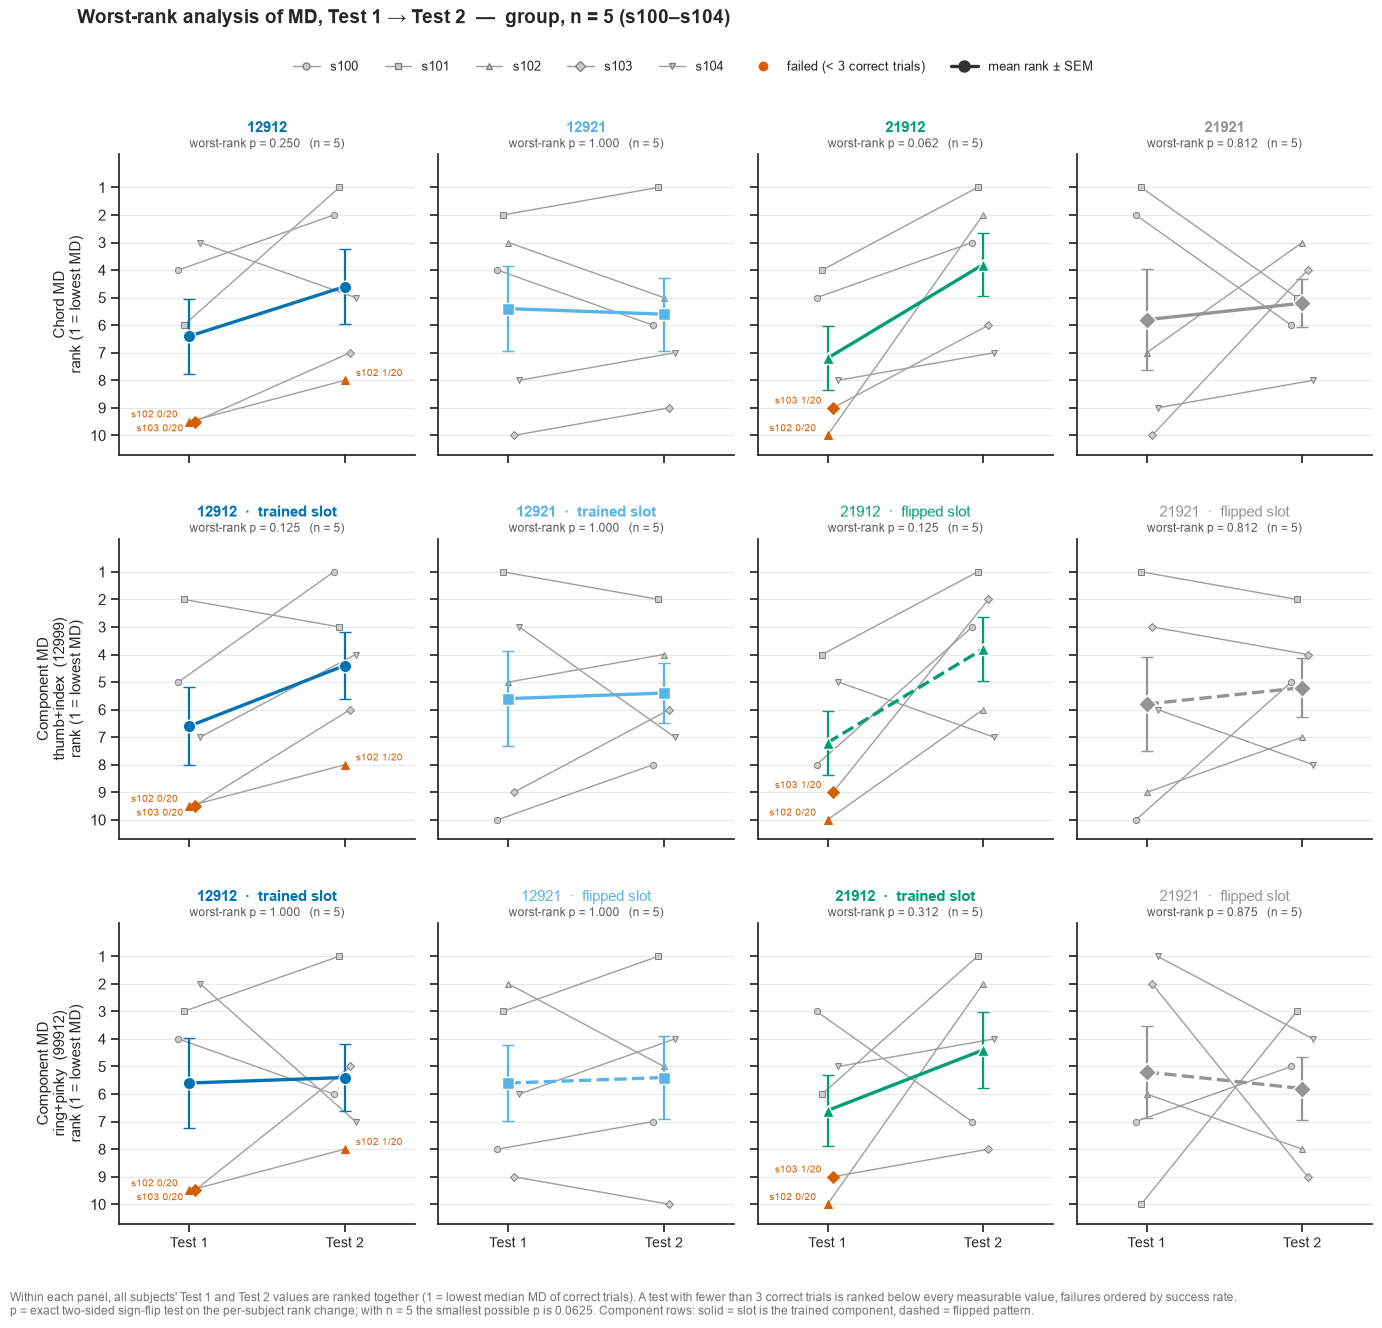

wrote figures/group/worst_rank/01_worst_rank_md.png


In [3]:
SUBJ_MARKER = dict(zip(SUBJECTS, ["o", "s", "^", "D", "v", "P", "X"]))
C_FAIL = "#D55E00"
xs = np.arange(len(PHASES))
SUBJ_DODGE = dict(zip(SUBJECTS, np.linspace(-.07, .07, len(SUBJECTS))))   # ties stay visible

fig, axes = plt.subplots(len(MEASURES), len(TESTED), figsize=(14, 4.0 * len(MEASURES) + 1.2),
                         sharex=True, sharey=True)
for r, ((label, _, _, slot), s) in enumerate(zip(MEASURES, tables)):
    for k, c in enumerate(TESTED):
        ax = axes[r, k]
        d = s[s.chordID == c]
        stacked = {}                          # (phase, rank) -> labels already placed there
        for sn, g in d.groupby("sn"):
            g = g.set_index("phase").reindex(list(PHASES))
            ax.plot(xs + SUBJ_DODGE[sn], g["rank"], color="0.62", lw=1, zorder=2)
            for x, (ph, row) in zip(xs + SUBJ_DODGE[sn], g.iterrows()):
                if np.isnan(row["rank"]):
                    continue
                fail = bool(row.failed)
                ax.plot(x, row["rank"], marker=SUBJ_MARKER[sn], ms=6 if fail else 4.5, zorder=3,
                        mfc=C_FAIL if fail else "0.8", mec=C_FAIL if fail else "0.5", mew=.7)
                if fail:
                    k_tie = stacked.setdefault((ph, row["rank"]), 0)
                    stacked[(ph, row["rank"])] += 1
                    ax.annotate(f"s{sn} {int(row.n_correct)}/{int(row.n_presented)}",
                                (x, row["rank"]),
                                xytext=(-8 if x < .5 else 8, 5 - 10 * k_tie), textcoords="offset points",
                                ha="right" if x < .5 else "left", va="center",
                                fontsize=7.5, color=C_FAIL)
        w = d.pivot(index="sn", columns="phase", values="rank")[list(PHASES)].dropna()
        m, e = w.mean(), w.std(ddof=1) / np.sqrt(len(w))
        ls = "-" if slot is None or roles.contains(c, slot) else "--"
        ax.errorbar(xs, m, yerr=e, color=COLOR[c], marker=MARKER[c], ms=9, lw=2.4, ls=ls,
                    capsize=4, elinewidth=1.6, mec="white", mew=1, zorder=4)
        rr = res[(res.measure == label.replace("\n", " ")) & (res.chordID == c)].iloc[0]
        ax.grid(axis="y", color="0.91", lw=.8); ax.set_axisbelow(True)
        ax.set_xlim(-.45, len(PHASES) - .55)
        title = str(c) if slot is None else \
            f"{c}  ·  {'trained' if roles.contains(c, slot) else 'flipped'} slot"
        ax.set_title(title, fontsize=10.5, color=COLOR[c], pad=16,
                     fontweight="bold" if slot is None or roles.contains(c, slot) else "normal")
        ax.text(.5, 1.015, f"worst-rank p = {rr.p_worst_rank:.3f}   (n = {rr.n})",
                transform=ax.transAxes, ha="center", va="bottom", fontsize=8.5, color="0.35")
        if k == 0:
            ax.set_ylabel(f"{label}\nrank (1 = lowest MD)", fontsize=10.5)

n_max = 2 * len(SUBJECTS)
axes[0, 0].set_ylim(n_max + .7, -.2)              # inverted: best rank at the top
axes[0, 0].set_yticks(range(1, n_max + 1))
for ax in axes[-1]:
    ax.set_xticks(xs); ax.set_xticklabels(list(PHASES), fontsize=10)

handles = [Line2D([], [], color="0.62", lw=1, marker=SUBJ_MARKER[sn], ms=5, mfc="0.8",
                  mec="0.5", label=f"s{sn}") for sn in SUBJECTS]
handles += [Line2D([], [], lw=0, marker="o", ms=6, mfc=C_FAIL, mec=C_FAIL,
                   label=f"failed (< {MIN_CORRECT} correct trials)"),
            Line2D([], [], color="0.2", lw=2.4, marker="o", ms=8, label="mean rank ± SEM")]
fig.legend(handles=handles, loc="upper center", ncol=len(handles), frameon=False,
           bbox_to_anchor=(.5, .965), fontsize=9.5)
fig.suptitle("Worst-rank analysis of MD, Test 1 → Test 2  —  group, n = 5 (s100–s104)",
             fontsize=13.5, fontweight="bold", x=.06, ha="left", y=.995, color="0.15")
fig.text(.012, .006,
         f"Within each panel, all subjects' Test 1 and Test 2 values are ranked together (1 = lowest "
         f"median MD of correct trials). A test with fewer than {MIN_CORRECT} correct trials is "
         "ranked below every measurable value, failures ordered by success rate.\n"
         "p = exact two-sided sign-flip test on the per-subject rank change; with n = 5 the "
         "smallest possible p is 0.0625. Component rows: solid = slot is the trained component, "
         "dashed = flipped pattern.",
         fontsize=8.5, color="0.45", ha="left")
fig.subplots_adjust(left=.09, right=.985, top=.885, bottom=.075, hspace=.28, wspace=.08)
fig.savefig(FIG_DIR / "01_worst_rank_md.png", dpi=200, facecolor="white")
plt.show()
print(f"wrote {(FIG_DIR / '01_worst_rank_md.png').relative_to(ROOT)}")